In [6]:
%pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kagglehub]
Note: you may need to restart the kernel to use updated packages.


In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

100%|██████████| 66.0M/66.0M [00:03<00:00, 21.3MB/s]

Extracting files...


Path to dataset files: /home/filonoa1/.cache/kagglehub/datasets/mlg-ulb/creditcardfraud/versions/3


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os

In [11]:
df = pd.read_csv(os.path.join(path, "creditcard.csv"))
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [12]:
# check how many values of each class are there. 1 means fraudulent

df['Class'].value_counts(normalize=False)

Class
0    284315
1       492
Name: count, dtype: int64

In [13]:
# check for number of missing values

df.isnull().sum().sum()

0

/tmp/ipykernel_280/1700360867.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([amount_no_fraud, amount_fraud], labels=["Non-fraud", "Fraud"])


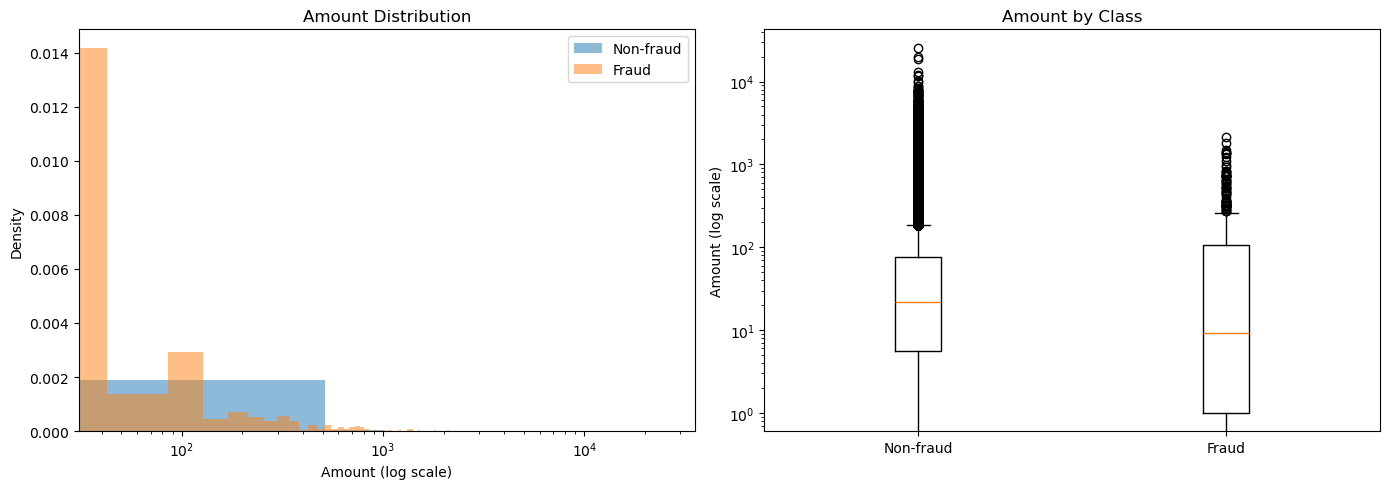

In [14]:
amount_fraud = df[df["Class"] == 1]["Amount"]
amount_no_fraud = df[df["Class"] == 0]["Amount"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram, log-scaled x-axis, normalized so fraud (492 rows) is visible next to non-fraud (284,315 rows)
axes[0].hist(amount_no_fraud, bins=50, alpha=0.5, label="Non-fraud", density=True)
axes[0].hist(amount_fraud, bins=50, alpha=0.5, label="Fraud", density=True)
axes[0].set_xscale("log")
axes[0].set_xlabel("Amount (log scale)")
axes[0].set_ylabel("Density")
axes[0].set_title("Amount Distribution")
axes[0].legend()

# Boxplot, log-scaled y-axis, good for comparing medians/spread directly
axes[1].boxplot([amount_no_fraud, amount_fraud], labels=["Non-fraud", "Fraud"])
axes[1].set_yscale("log")
axes[1].set_ylabel("Amount (log scale)")
axes[1].set_title("Amount by Class")

plt.tight_layout()
plt.show()

# Train logistic regression

In [70]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_curve, roc_auc_score, average_precision_score,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report


X = df.drop(columns=["Time", "Class"])
y = df["Class"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=2
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=2)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

In [66]:
print(confusion_matrix(y_test, y_pred))

[[55454  1410]
 [    5    93]]


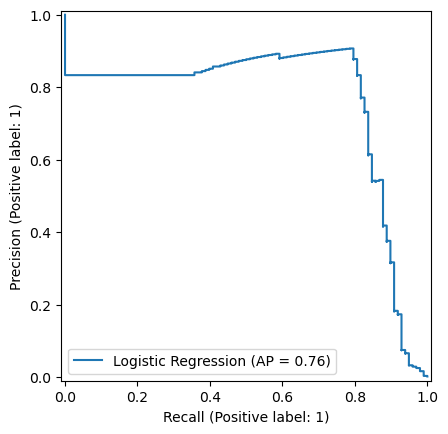

In [67]:
PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="Logistic Regression")
plt.show()

In [68]:
print(classification_report(y_test, y_pred, target_names=["Non-fraud", "Fraud"]))

              precision    recall  f1-score   support

   Non-fraud       1.00      0.98      0.99     56864
       Fraud       0.06      0.95      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.96      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [76]:
from sklearn.metrics import precision_recall_curve, auc

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall, precision)
print(f"PR-AUC: {pr_auc:.4f}")

PR-AUC: 0.7864


## Comments

PR-AUC = 0.7864
Log regr catches 95% of fraud but at the cost of 1400 false positives which would mean a LOT of manual work for human inspectors.

A lot of false positives 